# Notebook 3 — Visualize Results and Feedback (publication figures)

**What this notebook is for.** It turns the numbers from Notebooks 1-2 into the **figures for the paper**, plus the clinician-facing explanation. Each figure has a short note explaining **what it shows and why it belongs in the manuscript**.

**How to read a figure cell**
- The text above each figure tells you what the figure is, how to read its axes, and what "good" looks like.
- The code simply calls one plotting function and displays the result.
- Every figure is also saved as a PNG in `figures/`, so you can drop it straight into the paper.

**The figures are grouped by the question they answer**
1. **Localization / geometry** — where are the stitches? (fig 1-3)
2. **Ordinal scoring** — how good are they? (fig 4-6, 9, 12-16, 18, 20-21)
3. **Generalization** — does it hold on unseen operators/batches? (fig 6, 8, 19)
4. **Distributions & explainability** — features, importance, embeddings (fig 7, 17, 22-23)
5. **Failure gallery & attention** (fig 10, 11)
6. **Clinician-facing feedback text**

> Every score shown is the **geometric-consistency proxy**, not a clinical outcome, and it does not rate a human surgeon. Attention/occlusion maps show *where the model looks*, never proof of cause.

## Cell 1 — Set up and load the results from Notebooks 1-2

**What this cell does.** Finds the project, imports the plotting code, and loads the result tables.

**How it works:**
- Same folder-walking trick to locate the project and import `sutureqc`.
- It loads three things from Notebook 2's output: the stitch geometry (`geo`), the model predictions, and the ablation table.
- `primary` is the headline result: only the rows for the **hybrid ("Dale")** model on the **grouped test** split. Most figures are built from this.
- `show_result()` is a helper that displays either a live figure or an already-saved PNG, so every figure cell looks the same.

**What you should see:** the repo path, the figures folder, the number of stitch rows (about 919) and the shape of the primary predictions.

In [1]:
import json
import sys
from pathlib import Path

# Locate the project root so the sutureqc package can be imported.
REPO = Path.cwd()
while REPO != REPO.parent and not (REPO / "src" / "sutureqc").exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))

import matplotlib.pyplot as plt  # inline display + closing figures
import pandas as pd              # tables
from IPython.display import Image, display

from sutureqc import config, modeling, viz

# Helper: figures returned as a live Figure are shown directly; existing figure
# functions return a saved PNG path, which is shown as an image instead.
def show_result(result):
    if result is None:
        print("(not available - a prerequisite artifact may be missing)")
        return
    if hasattr(result, "savefig"):
        display(result)
        plt.close(result)
    else:
        display(Image(str(result)))

print("repository:", REPO)
print("figures dir:", config.FIGURES_DIR)


repository: D:\REU_new_dataset
figures dir: D:\REU_new_dataset\figures


In [2]:
# Load the artifacts written by Notebooks 1 and 2.
geo = modeling.load_geometry_table()                       # stitch + geometry + proxy + split
predictions = viz.load_predictions()                        # None if Notebook 2 has not run
primary = None
if predictions is not None and not predictions.empty:
    primary = predictions[(predictions["fold"] == "grouped_test") & (predictions["model"] == "hybrid")]
ablation = pd.read_csv(config.ABLATION_METRICS_CSV) if config.ABLATION_METRICS_CSV.exists() else None
print("stitch rows        :", geo.shape)
print("primary predictions:", None if primary is None else primary.shape)

stitch rows        : (919, 57)
primary predictions: (215, 19)


## FIG 1 — Frames with stitch bounding boxes

**What it shows.** Real endoscope frames with each annotated stitch box drawn (blue) and numbered.

**How to read it.** Each panel is one frame; the blue rectangles are the human annotations of where stitches are.

**Why it is in the paper.** It establishes the raw data and the localization annotation — the reader must see what a "stitch" looks like before any score is discussed.

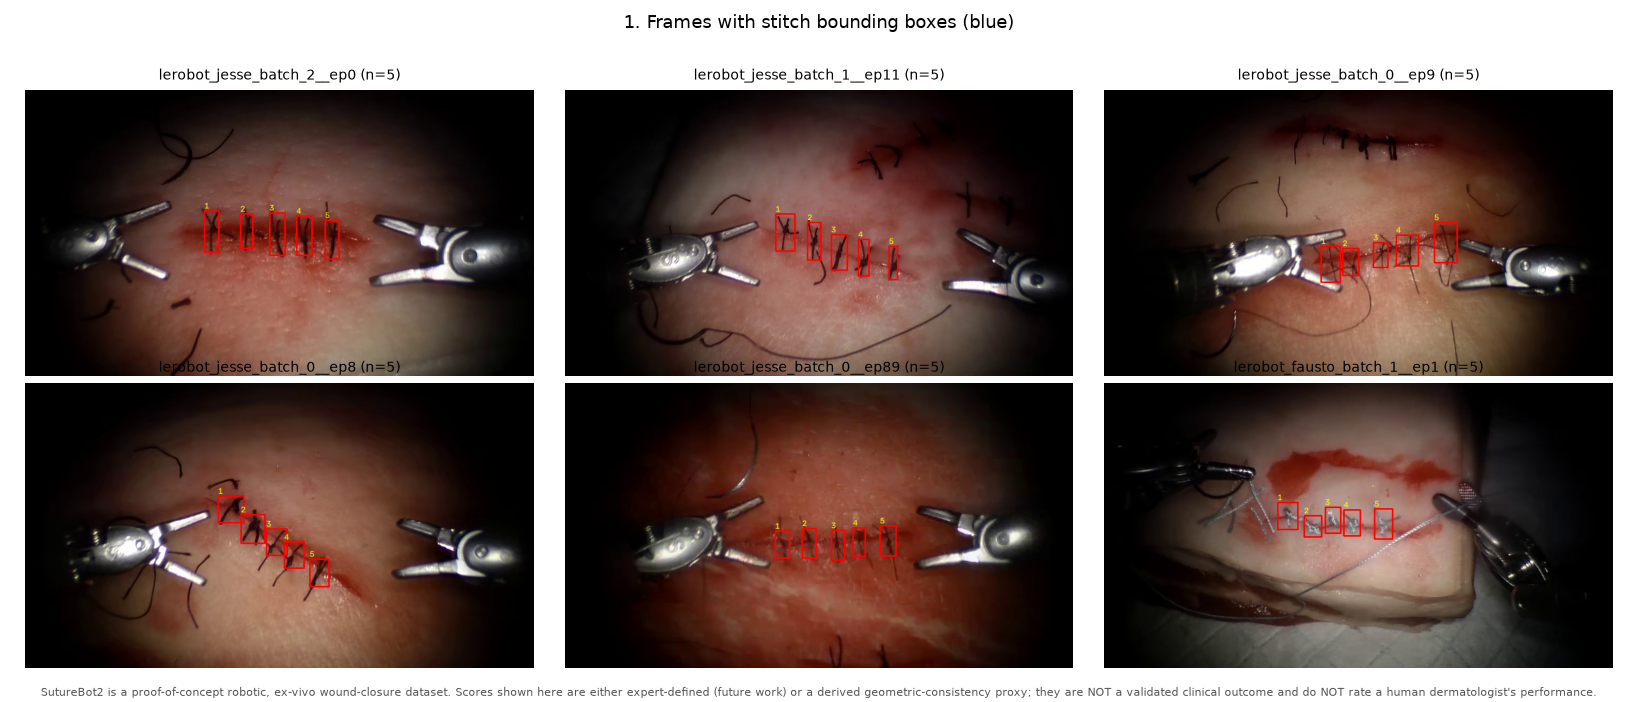

In [3]:
# fig01: frames with their stitch bounding boxes.
show_result(viz.plot_frame_with_boxes(geo))

## FIG 2 — Stitch crops with predicted score and confidence

**What it shows.** A sample of individual stitch crops, each titled with the true score, the predicted score and the model's confidence.

**How to read it.** Compare the title pair, e.g. `true 4 / pred 4` is a hit, `true 5 / pred 3` is a two-step miss.

**Why it is in the paper.** It lets a reader (and a surgeon) eyeball what the model sees and judge whether the scores look sensible.

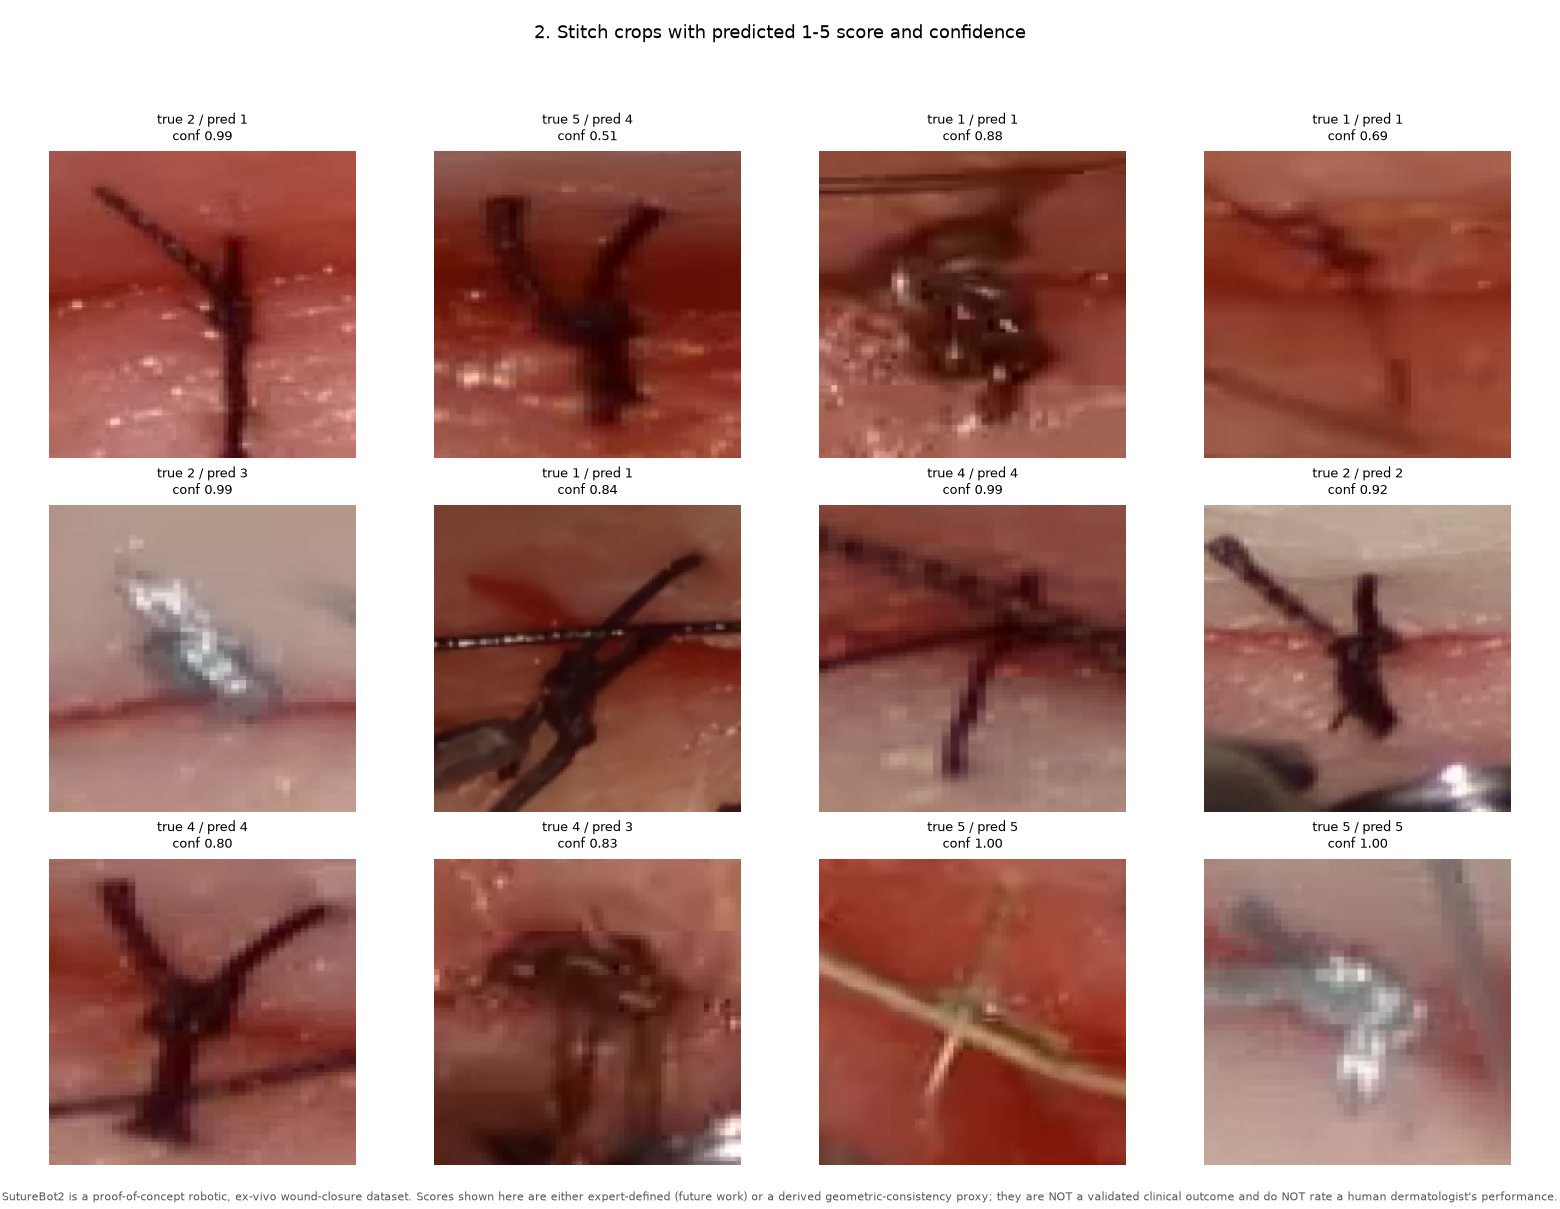

In [4]:
# fig02: stitch crops with true/predicted score and confidence.
if primary is not None:
    show_result(viz.plot_stitch_crops_with_scores(primary))

## FIG 3 — Wound mask overlay and stitch locations

**What it shows.** Frames with the wound mask tinted green, plus the stitch box and centre point.

**How to read it.** Green = the wound region. The box/centre show where the stitch sits relative to the wound — this is the basis of the interpretable geometry.

**Why it is in the paper.** The whole explainability claim rests on wound-relative geometry, so the reader must see the mask and the stitch together.

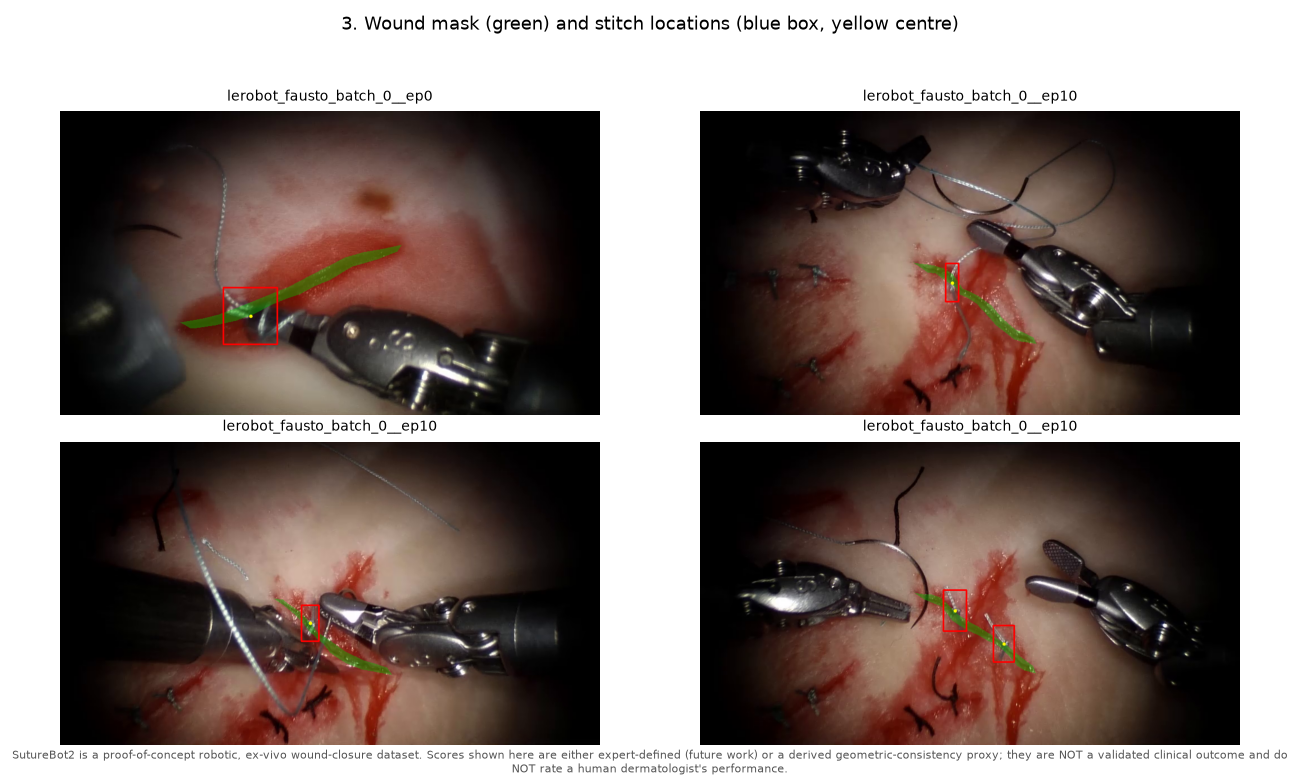

In [5]:
# fig03: wound mask overlay + stitch locations.
show_result(viz.plot_wound_mask_overlay(geo))

## FIG 4 — Ground-truth vs predicted score (heatmap)

**What it shows.** A grid where rows are the true score and columns are the predicted score, coloured by how many stitches fell in each cell.

**How to read it.** The diagonal is perfect; the two cells next to it are "off by one"; anything far from the diagonal is a real error.

**Why it is in the paper.** It is the simplest, clearest summary of ordinal model quality.

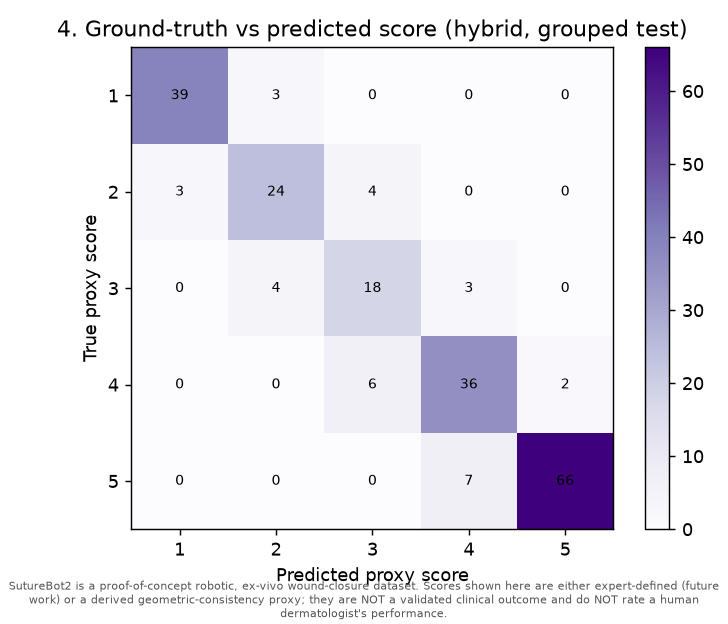

In [6]:
# fig04: true vs predicted score heatmap.
if primary is not None:
    show_result(viz.plot_gt_vs_pred(primary))

## FIG 5 — Confusion matrix + ordinal error matrix

**What it shows.** Left: the confusion matrix (counts). Right: the same idea but each cell is weighted by *how far off* the prediction was.

**How to read it.** The left matrix tells you *where* mistakes happen; the right matrix tells you *how serious* they are (darker far from the diagonal = worse mistakes).

**Why it is in the paper.** Standard reporting for classifiers, and the error matrix specifically suits an ordered target.

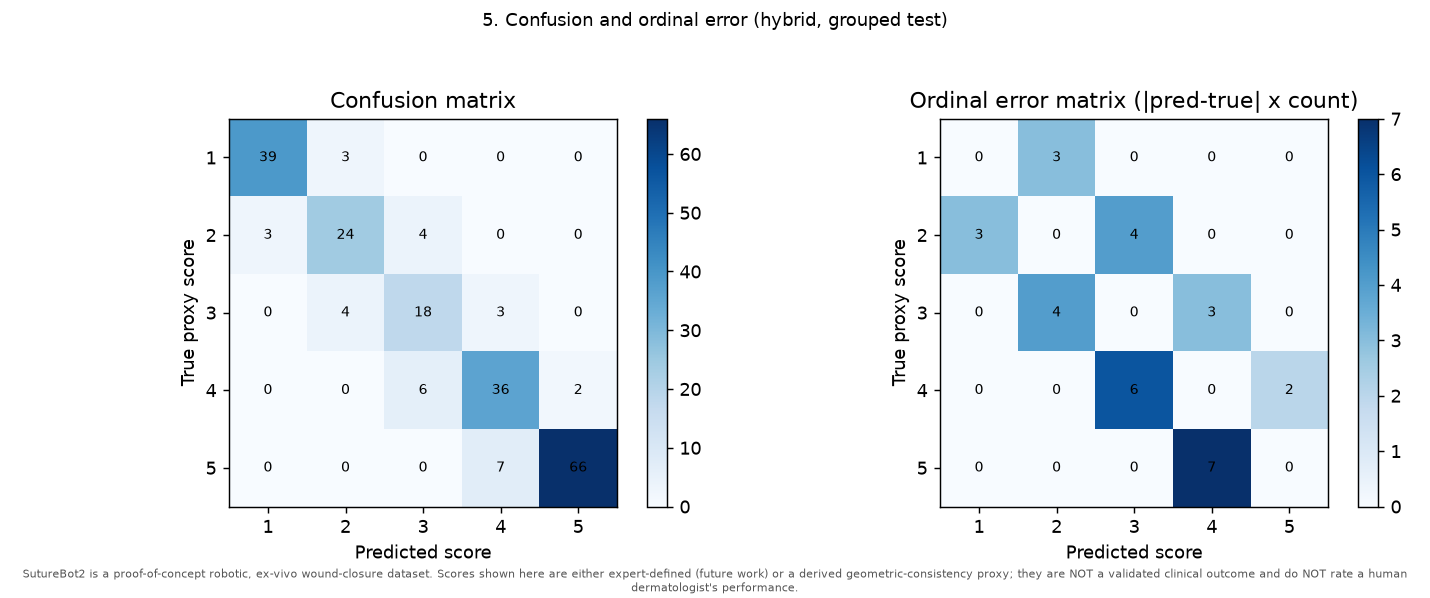

In [7]:
# fig05: confusion + ordinal error matrix.
if primary is not None:
    show_result(viz.plot_confusion_and_error_matrix(primary))

## FIG 12 — One-vs-rest ROC curves

**What it shows.** For each score 1-5, an ROC curve of "this score vs all the others", with its AUC, plus the average (macro) AUC in the title.

**How to read it.** AUC goes from 0.5 (random) to 1.0 (perfect). Curves that bow toward the top-left are better.

**Why it is in the paper.** ROC/AUC is the most commonly reported discrimination metric in the surgical-AI literature, so including it makes the work comparable.

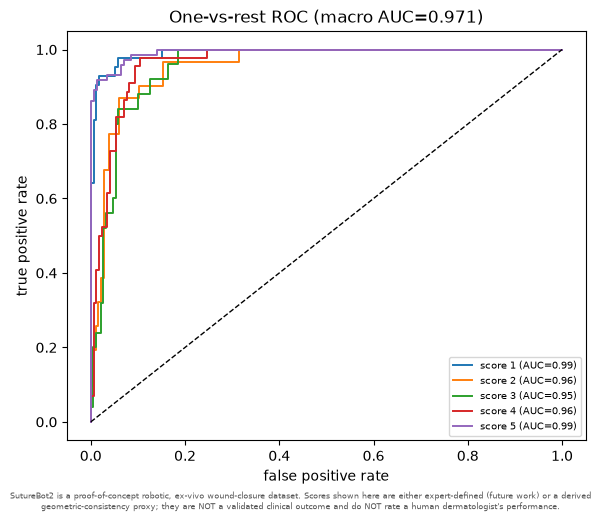

In [8]:
# fig12: one-vs-rest ROC curves with macro AUC.
if primary is not None:
    show_result(viz.plot_roc_curves(primary))

## FIG 13 — Binary ROC: acceptable (>=3) vs poor (<3)

**What it shows.** The ordinal target collapsed into a two-class question — is the stitch acceptable? — with a single ROC curve and AUC.

**How to read it.** The AUC tells you how well the model separates acceptable from poor stitches.

**Why it is in the paper.** Much of the reviewed literature uses binary pass/fail, so this figure connects the ordinal model to that common framing.

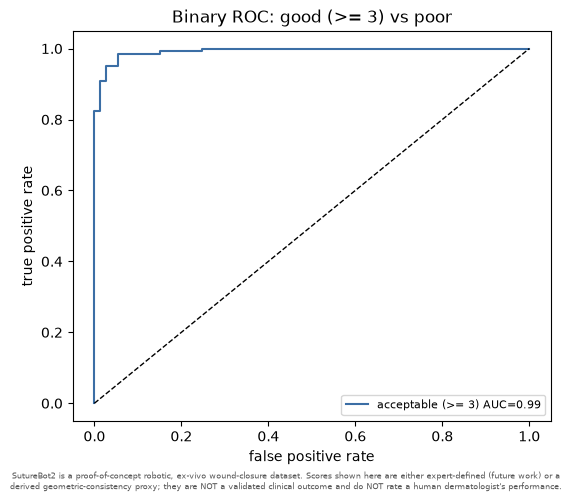

In [9]:
# fig13: binary ROC for acceptable (>=3) vs poor.
if primary is not None:
    show_result(viz.plot_binary_roc(primary))

## FIG 14 — Precision-recall curves

**What it shows.** One-vs-rest precision-recall curves with the average precision (AP) per class.

**How to read it.** Precision = "when it says this score, how often is it right?"; recall = "of all true instances of this score, how many did it catch?". The curve trades one against the other.

**Why it is in the paper.** PR is more informative than ROC when classes are uneven, which they are here.

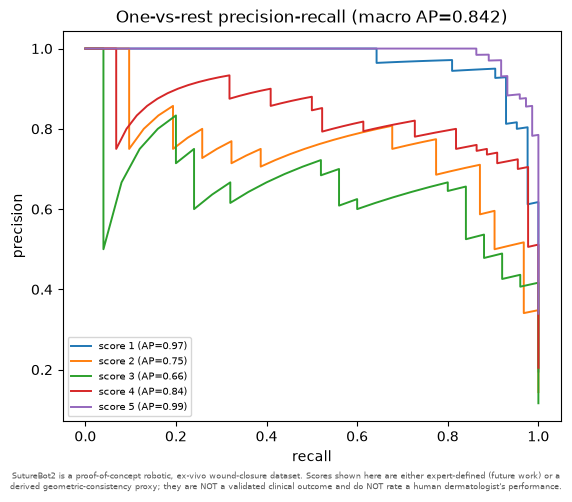

In [10]:
# fig14: one-vs-rest precision-recall curves.
if primary is not None:
    show_result(viz.plot_precision_recall(primary))

## FIG 15 — True-vs-predicted scatter

**What it shows.** Each test stitch as a dot: x = true score (slightly jittered so dots don't overlap), y = the model's continuous predicted score. Colour = size of the error, dot size = confidence.

**How to read it.** The closer the cloud hugs the dashed diagonal, the better. Tight vertical clusters mean confident predictions.

**Why it is in the paper.** It shows the *ranking* quality and the model's confidence at once — things a confusion matrix hides.

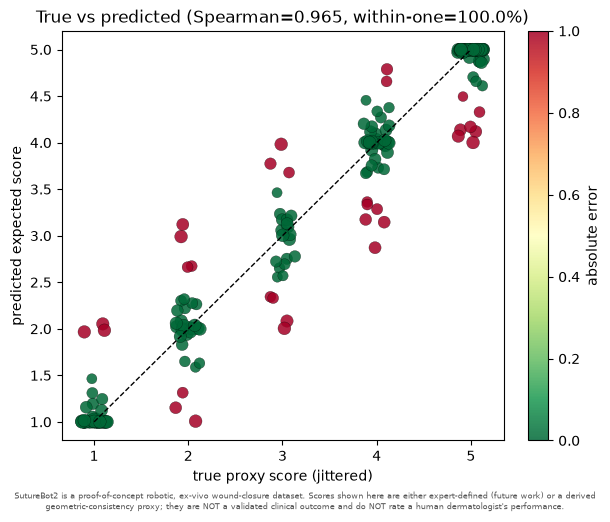

In [11]:
# fig15: true vs predicted continuous-score scatter.
if primary is not None:
    show_result(viz.plot_true_vs_pred_scatter(primary))

## FIG 16 — Confidence vs error

**What this cell does.** Shows whether the model's confidence means anything.

**How it shows it.** Each dot is a stitch: x = confidence, y = absolute error. The red line is the average error within confidence bins.

**How to read it.** A downward-sloping line is good: high-confidence predictions have small errors. A flat line would mean confidence is meaningless.

**Why it is in the paper.** Honest confidence is required for the "flag uncertain cases for review" feature.

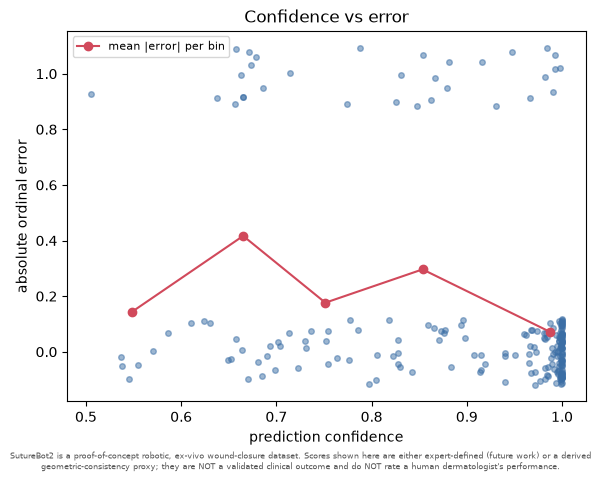

In [12]:
# fig16: confidence vs absolute error.
if primary is not None:
    show_result(viz.plot_confidence_vs_error(primary))

## FIG 18 — Per-class precision / recall / F1 (heatmap)

**What it shows.** A row for precision, recall and F1, and a column for each score 1-5.

**How to read it.** Each cell is 0-1; higher is better. It quickly reveals which score levels are hard (often the middle or the extremes).

**Why it is in the paper.** Per-class metrics show *where* the model is weak, not just an overall average.

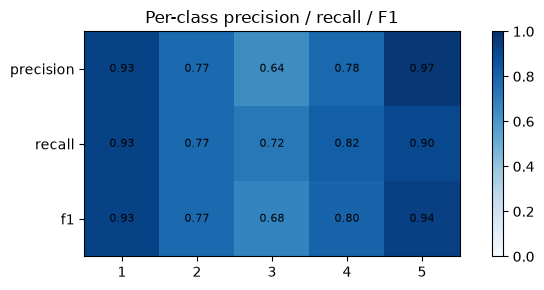

In [13]:
# fig18: per-class precision/recall/F1 heatmap.
if primary is not None:
    show_result(viz.plot_per_class_metrics(primary))

## FIG 20 — Predicted probability per instance (heatmap)

**What it shows.** Each row is one test stitch (sorted by its true score, with cyan lines separating the true-score blocks), and the five columns are the probabilities the model gave to scores 1-5.

**How to read it.** Bright cells show the model's belief. If the brightest cell in each row is near the correct block, the model is doing well.

**Why it is in the paper.** It is a compact picture of confidence and ordering across all test stitches at once.

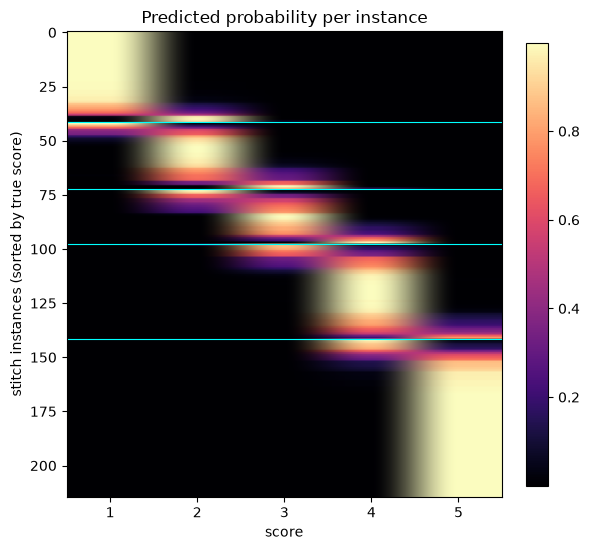

In [14]:
# fig20: per-instance probability heatmap.
if primary is not None:
    show_result(viz.plot_probability_heatmap(primary))

## FIG 21 — Residual histogram

**What it shows.** A histogram of the signed error `predicted - true`.

**How to read it.** A tall bar at 0 means most predictions are exact; bars at +/-1 mean one-step errors. The shape should be centred on 0.

**Why it is in the paper.** It proves the errors are small and unbiased (not systematically too high or too low).

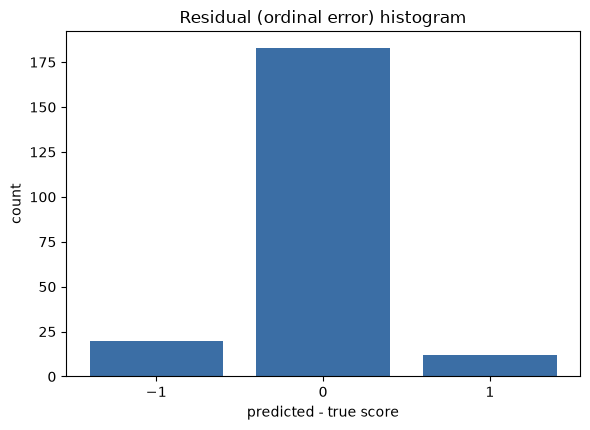

In [15]:
# fig21: residual (ordinal error) histogram.
if primary is not None:
    show_result(viz.plot_residual_histogram(primary))

## FIG 9 — Calibration

**What it shows.** The model's average confidence (x) against how often it was actually correct (y), compared with the dashed "perfect calibration" line.

**How to read it.** Points on the dashed line mean "confidence 0.8 really means 80% correct". Points below mean over-confidence; above mean under-confidence.

**Why it is in the paper.** A model whose confidence is trustworthy can safely say "I'm not sure — review this one".

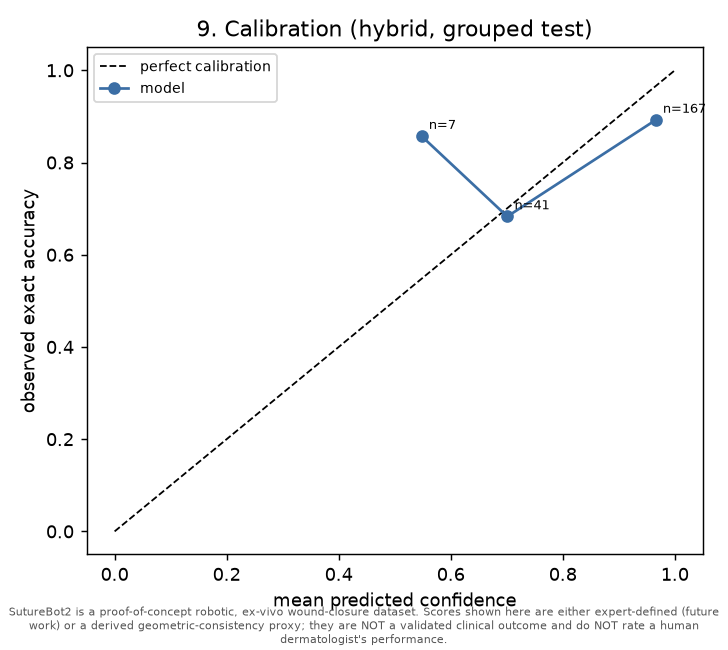

In [16]:
# fig09: calibration plot.
if primary is not None:
    show_result(viz.plot_calibration(primary))

## FIG 6 — Metrics by fold (grouped test, grouped CV, leave-one-batch-out)

**What it shows.** Three stacked bar charts: MAE, quadratic kappa and Spearman, one bar per evaluation fold.

**How to read it.** Bars from the leave-one-batch-out folds show performance on unseen operators; they are usually worse than the grouped test — that gap *is* the generalization story.

**Why it is in the paper.** Reviewers want to see how results hold up across folds and on held-out operators.

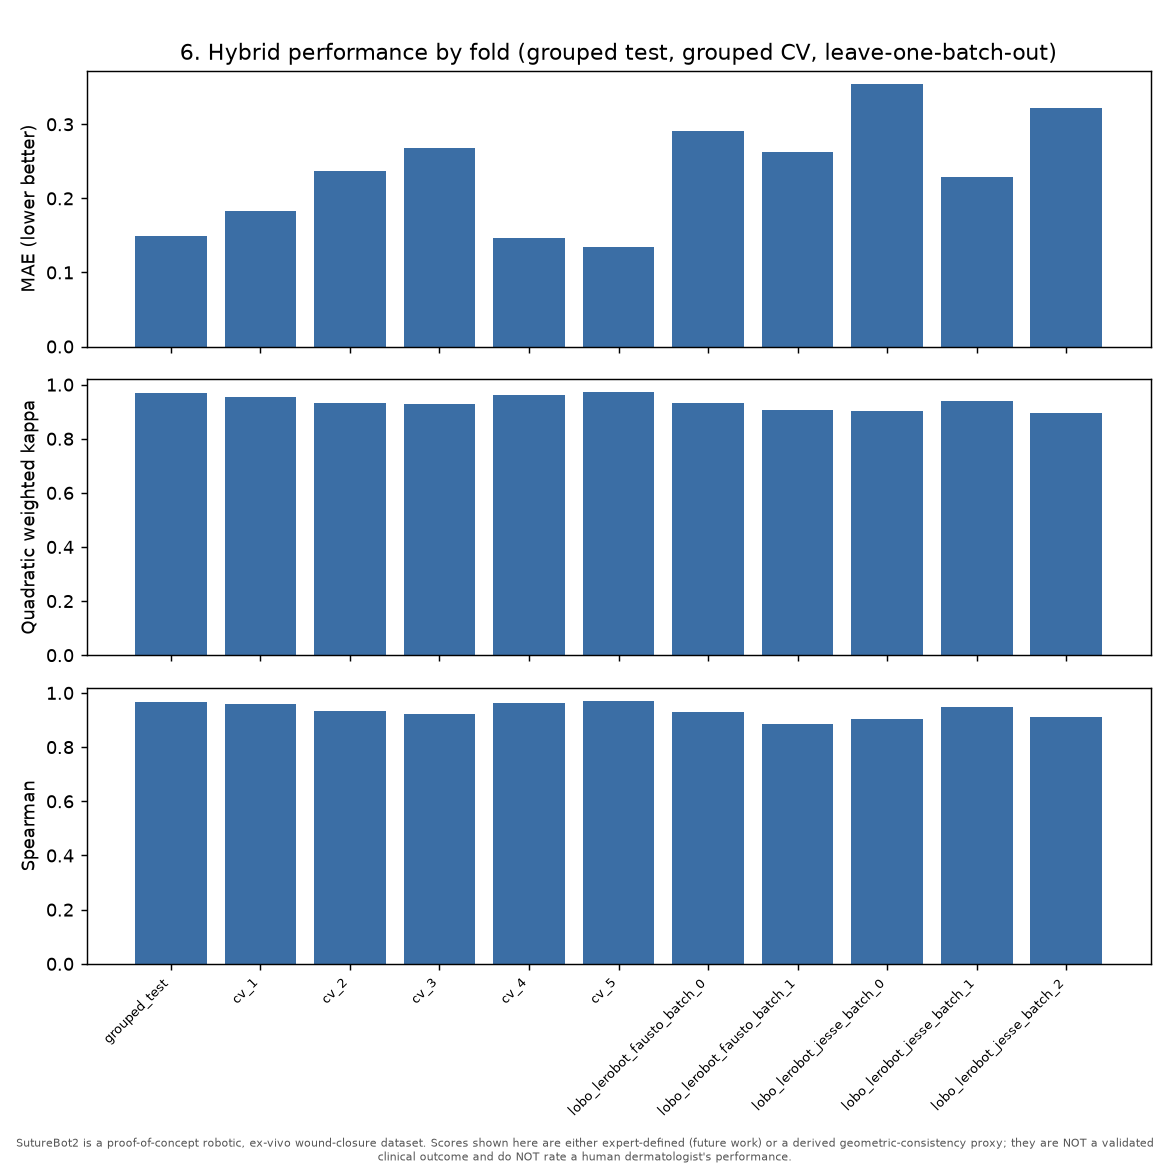

In [17]:
# fig06: hybrid metrics across grouped test, CV and leave-one-batch-out.
if ablation is not None:
    show_result(viz.plot_metrics_by_fold(ablation))

## FIG 8 — Ablation comparison (geometry-only vs image-only vs hybrid)

**What it shows.** Two bar charts on the grouped test split: MAE (left, lower is better) and within-one accuracy (right, higher is better, with the 80% target line) for each model.

**How to read it.** It directly answers "does adding the image to geometry help, and does adding geometry to the image help?".

**Why it is in the paper.** This is the central contribution figure — the ablation that justifies the fusion design.

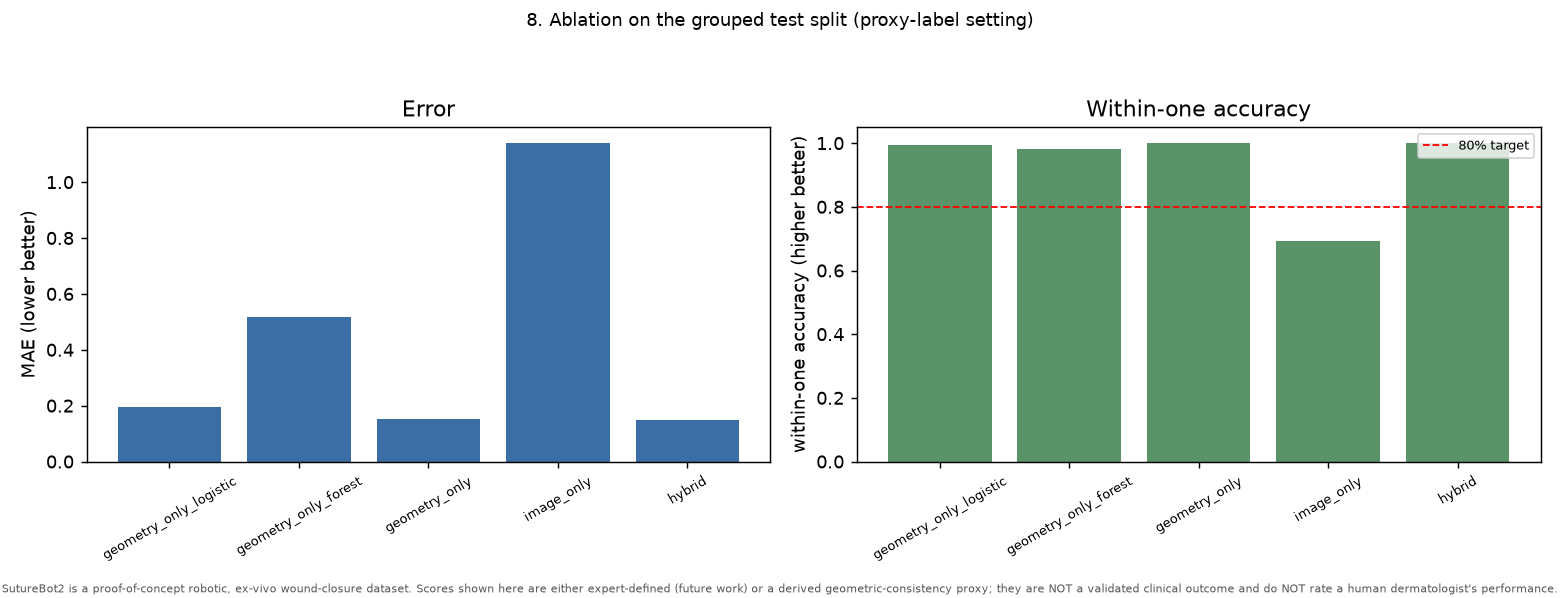

In [18]:
# fig08: ablation comparison on the grouped test split.
if ablation is not None:
    show_result(viz.plot_ablation_comparison(ablation))

## Results table — exact / within-one / MAE side by side

**What this cell does.** Builds one compact table so the three headline numbers — **exact accuracy**, **within-one accuracy** and **MAE** — for every model sit next to each other, ranked best-first.

**How to read it.** Higher exact and within-one is better; lower MAE is better. The proposed hybrid ("Dale") row should sit at the top; `image_only` shows how weak the picture alone is.

In [19]:
# Compact results table: exact accuracy and within-one accuracy sit right next to MAE.
cols = ["model", "n", "exact_accuracy", "within_one_accuracy", "mae"]
if ablation is not None:
    headline = (ablation[ablation["fold"] == "grouped_test"][cols]
                .sort_values("exact_accuracy", ascending=False)
                .reset_index(drop=True))
    headline["exact_accuracy"] = (headline["exact_accuracy"] * 100).round(1)
    headline["within_one_accuracy"] = (headline["within_one_accuracy"] * 100).round(1)
    headline = headline.rename(columns={"exact_accuracy": "exact (%)",
                                        "within_one_accuracy": "within-one (%)",
                                        "mae": "MAE"})
    display(headline)
else:
    print("ablation table unavailable - run Notebook 2 first")

,model,n,exact (%),within-one (%),MAE
0,hybrid,215,85.1,100.0,0.148837
1,geometry_only,215,84.7,100.0,0.153488
2,geometry_only_logistic,215,80.9,99.5,0.195349
3,geometry_only_forest,215,50.2,98.1,0.516279
4,image_only,215,21.9,69.3,1.139535


## FIG 19 — Batch x score composition (heatmap)

**What it shows.** Each row is an operator batch; each column is a proxy score; cells are the *fraction* of that batch's stitches at that score (annotated with the fraction).

**How to read it.** Rows that look different from each other mean the batches are not alike — an operator/recording shift.

**Why it is in the paper.** It documents the batch shift that makes grouped evaluation necessary.

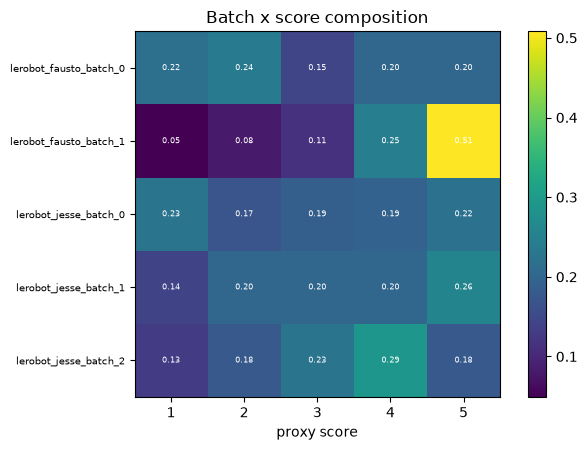

In [20]:
# fig19: batch x score composition.
show_result(viz.plot_batch_score_heatmap(geo))

## FIG 7 — Score distribution by batch and semantic sub-task

**What it shows.** Two stacked bar charts: how the proxy score is distributed across batches, and across the most common sub-task labels.

**How to read it.** It shows which scores are common and whether certain contexts (sub-tasks) skew the scores.

**Why it is in the paper.** Understanding the label distribution is required to interpret every other result.

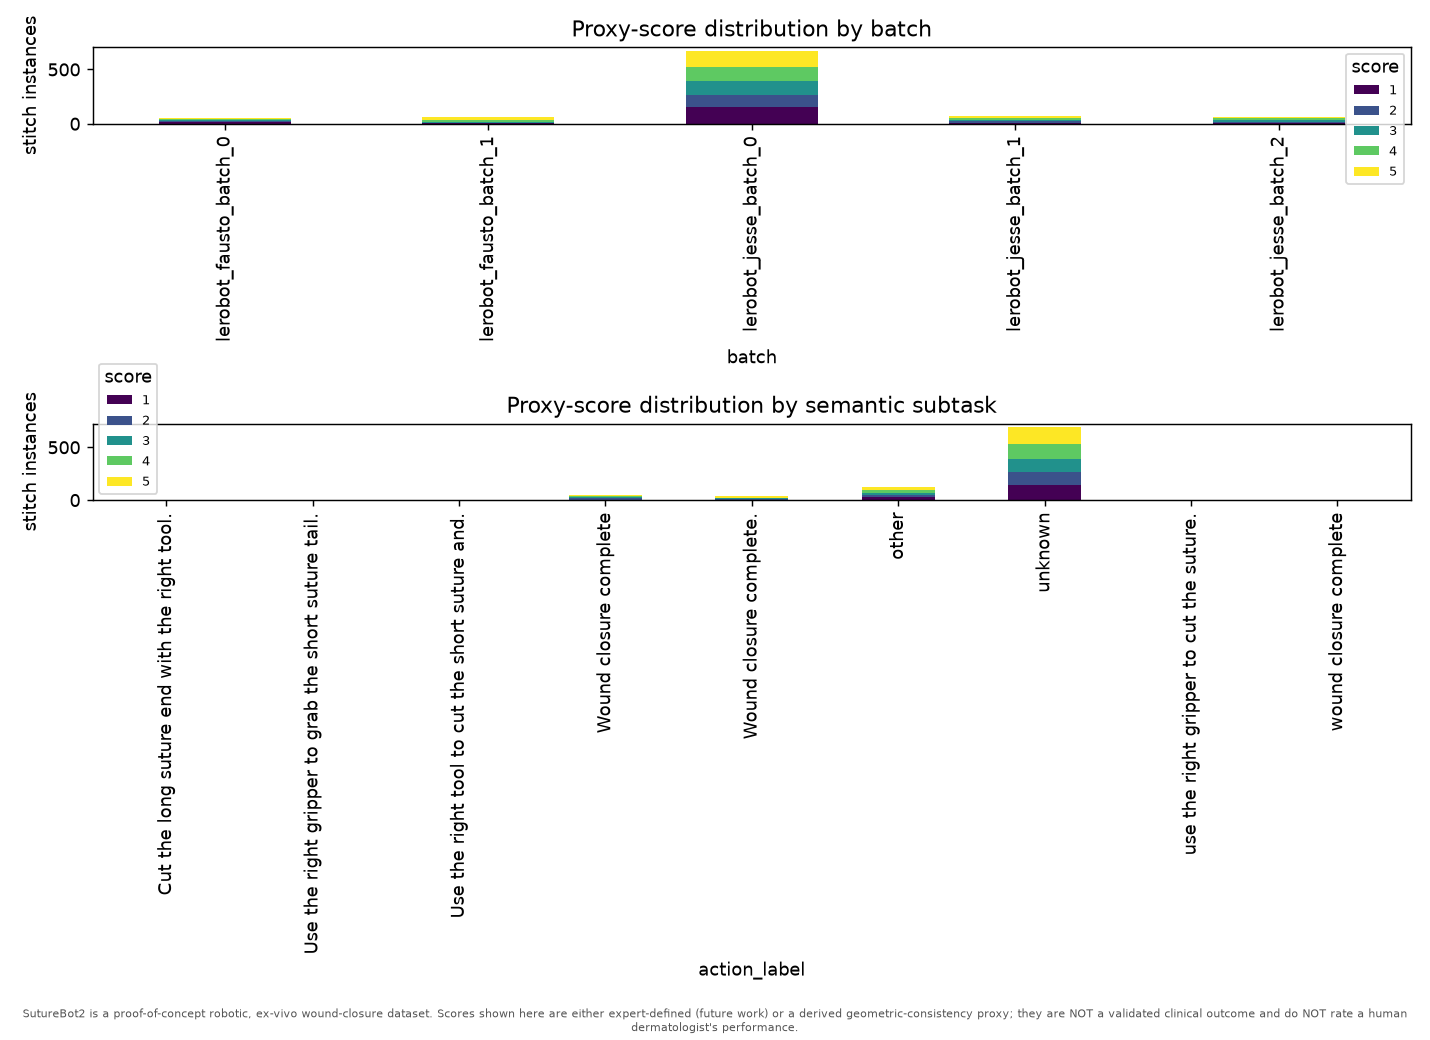

In [21]:
# fig07: proxy-score distribution by batch and by semantic sub-task.
show_result(viz.plot_score_distribution_by_batch_and_action(geo))

## FIG 17 — Geometry feature correlation heatmap

**What it shows.** A matrix of correlations between every geometry feature (and the continuous proxy). Blue = negative, red = positive, white near 0.

**How to read it.** Strong blocks of colour mean features carry the same information (redundancy), which can destabilise models.

**Why it is in the paper.** It justifies feature selection and documents multicollinearity among engineered features.

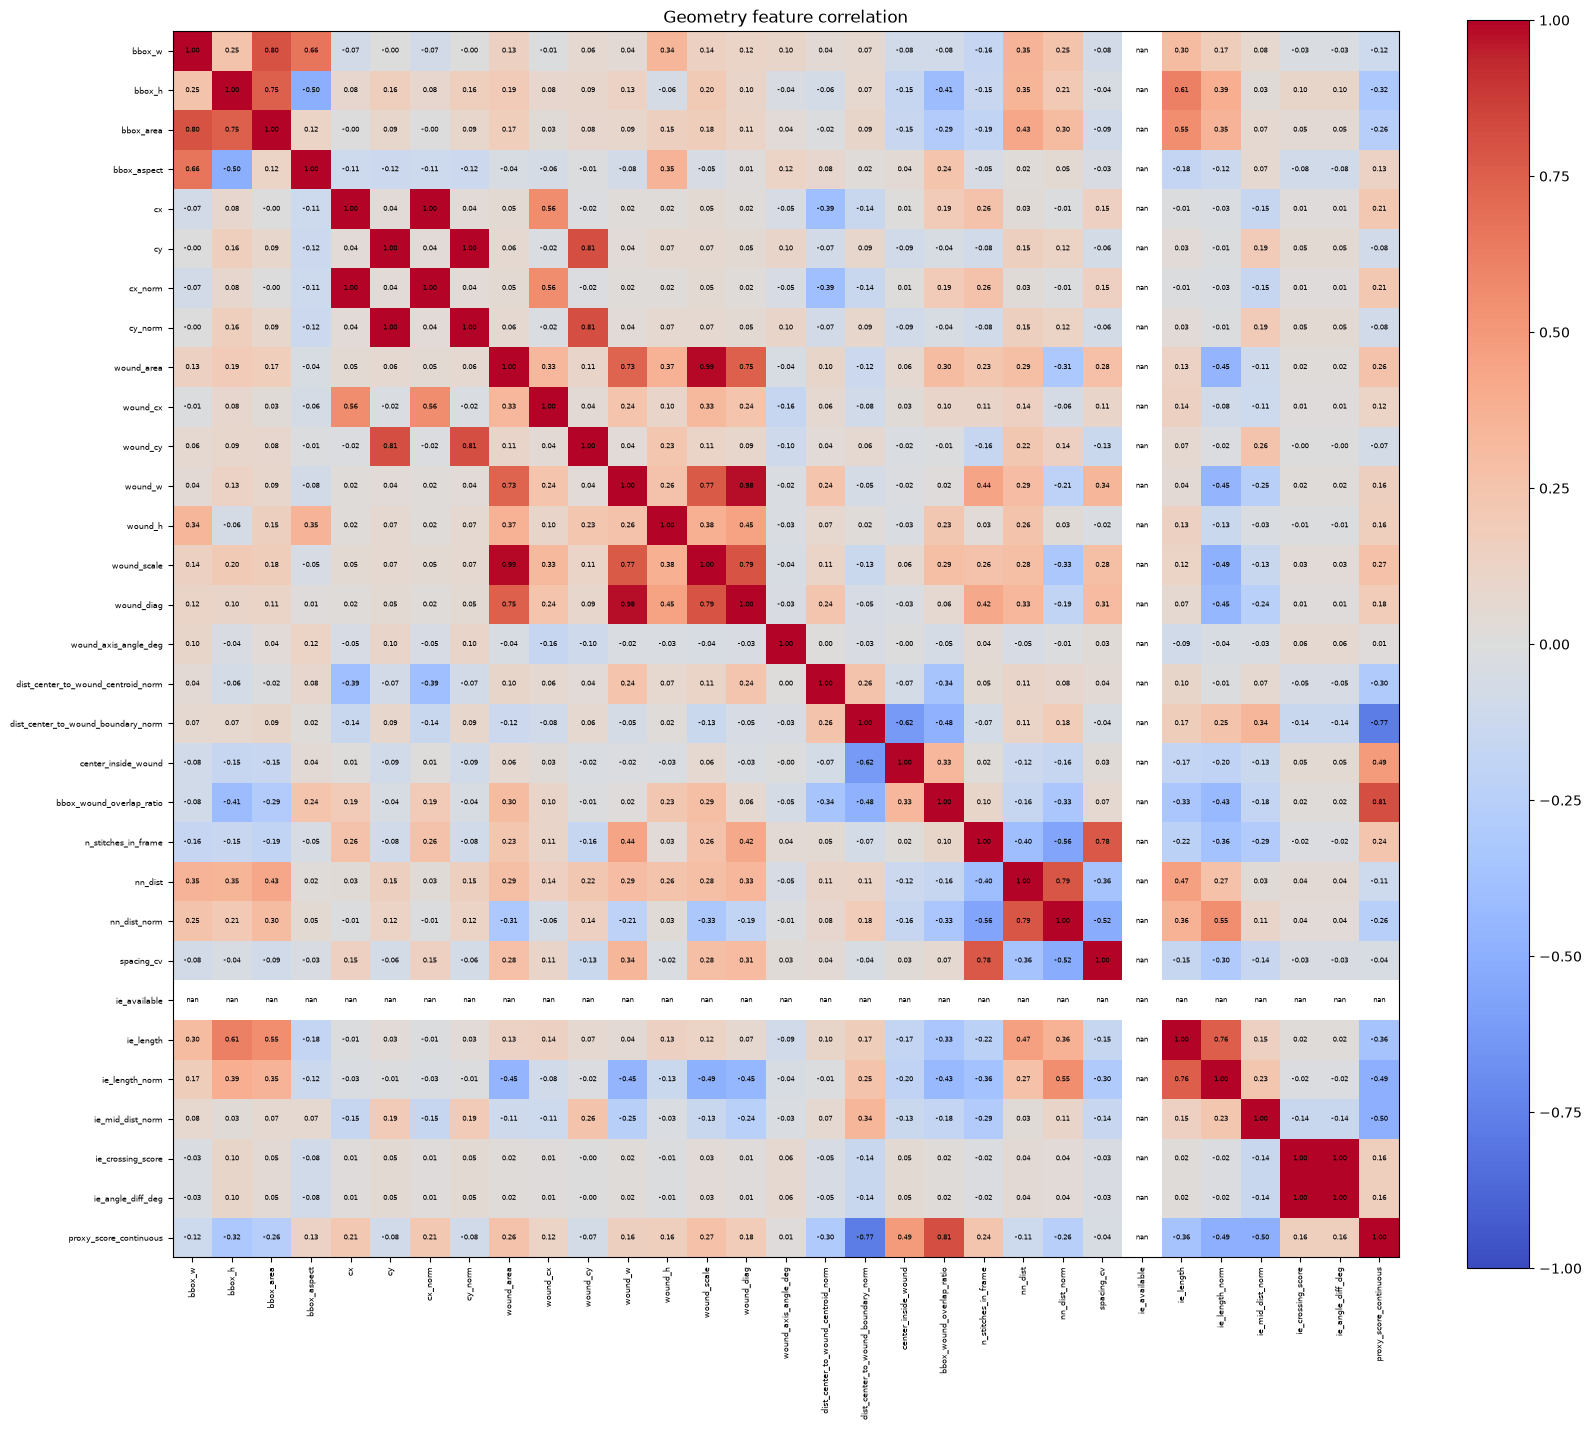

In [22]:
# fig17: geometry feature correlation heatmap.
show_result(viz.plot_geometry_correlation_heatmap(geo))

## FIG 22 — Projection of frozen image embeddings (PCA / t-SNE)

**What it shows.** The 512-number image descriptions squashed into 2D, with each dot coloured by its proxy score.

**How to read it.** If dots of similar colour cluster together, the frozen features already separate score levels; if they are mixed, the image alone is not very informative.

**Why it is in the paper.** It is a quick, honest check of what the visual features actually capture.

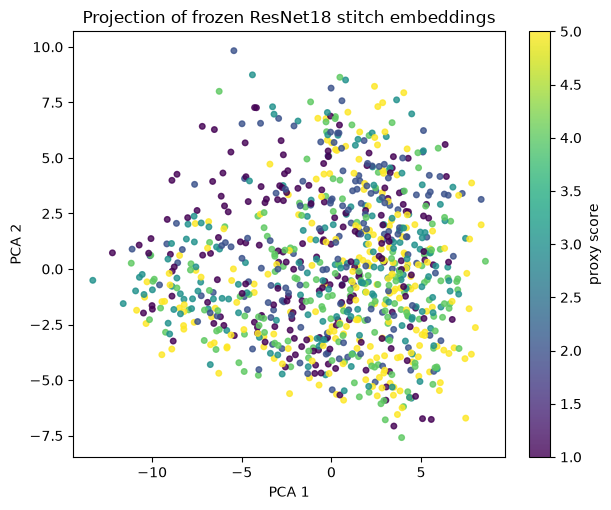

In [23]:
# fig22: PCA (or t-SNE) projection of the frozen image embeddings.
show_result(viz.plot_embedding_projection(features=geo))

## FIG 23 — Geometry feature importance (explainability)

**What it shows.** A horizontal bar chart of how useful each geometry feature is to a random-forest model of the score.

**How to read it.** Longer bars = more important features. These are the "measurable reasons" behind a score.

**Why it is in the paper.** It is the model-agnostic explainability companion (in the spirit of SHAP), naming the drivers of the score.

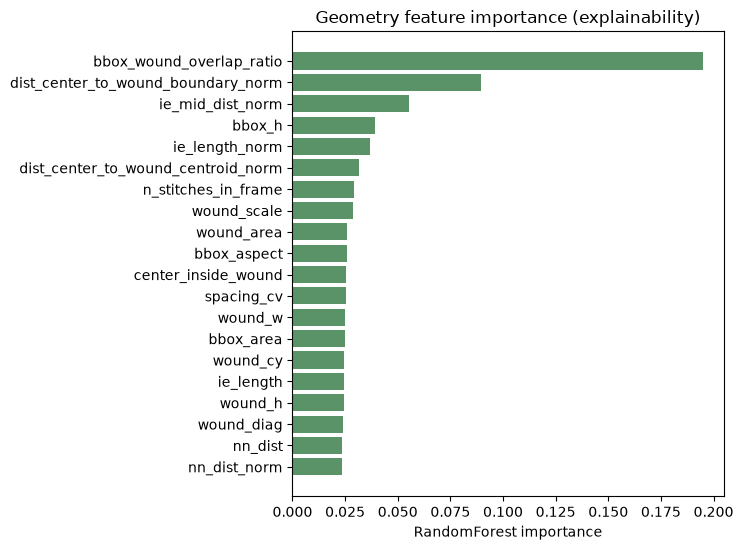

In [24]:
# fig23: geometry feature importance (explainability).
show_result(viz.plot_feature_importance())

## FIG 24 — Training curves

**What it shows.** Training loss and validation MAE over epochs for each model variant (written by Notebook 2).

**How to read it.** The loss should fall and then flatten; the validation MAE shows when early stopping kicked in.

**Why it is in the paper.** It documents that training was stable and not overfit.

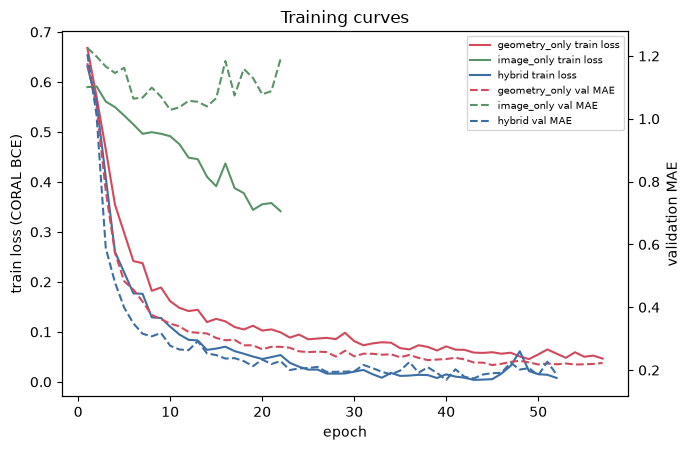

In [25]:
# fig24: training curves (requires Notebook 2 to have run).
hist_path = config.MODELS_DIR / "histories.json"
histories = json.loads(hist_path.read_text()) if hist_path.exists() else None
if histories:
    show_result(viz.plot_training_curves(histories))
else:
    print("Training histories unavailable: run Notebook 2 first.")

## FIG 10 — Failure gallery

**What it shows.** The stitches with the worst ordinal errors, each tagged with a suspected cause (occlusion, ambiguous box, or the hardest batch shift).

**How to read it.** These are the cases the model got badly wrong; look at the crop to see why.

**Why it is in the paper.** An honest failure analysis; reviewers expect the limitations to be shown, not hidden.

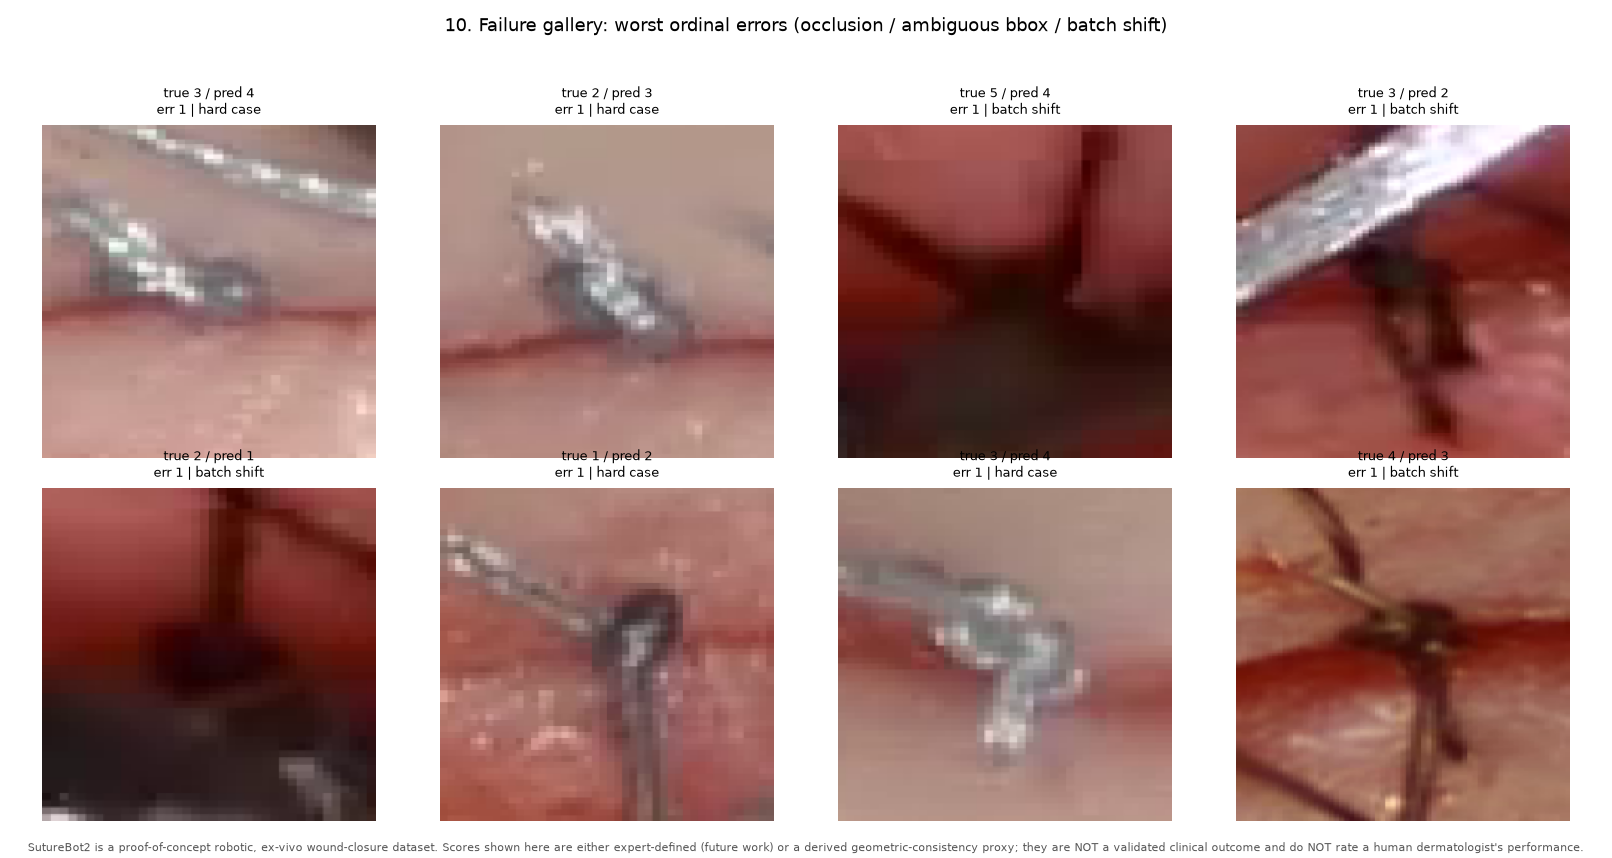

In [26]:
# fig10: worst-case failure gallery.
if primary is not None:
    show_result(viz.plot_failure_gallery(primary))

## FIG 11 — Occlusion sensitivity (model attention)

**What it shows.** For a few crops, the top row is the image and the bottom row is a heatmap of how much the prediction drops when each small patch is hidden.

**How to read it.** Brighter patches are regions the model relies on most.

**Why it is in the paper.** It is interpretability for the *image* branch — clearly labelled as "where the model looks", which is **not** causal evidence.

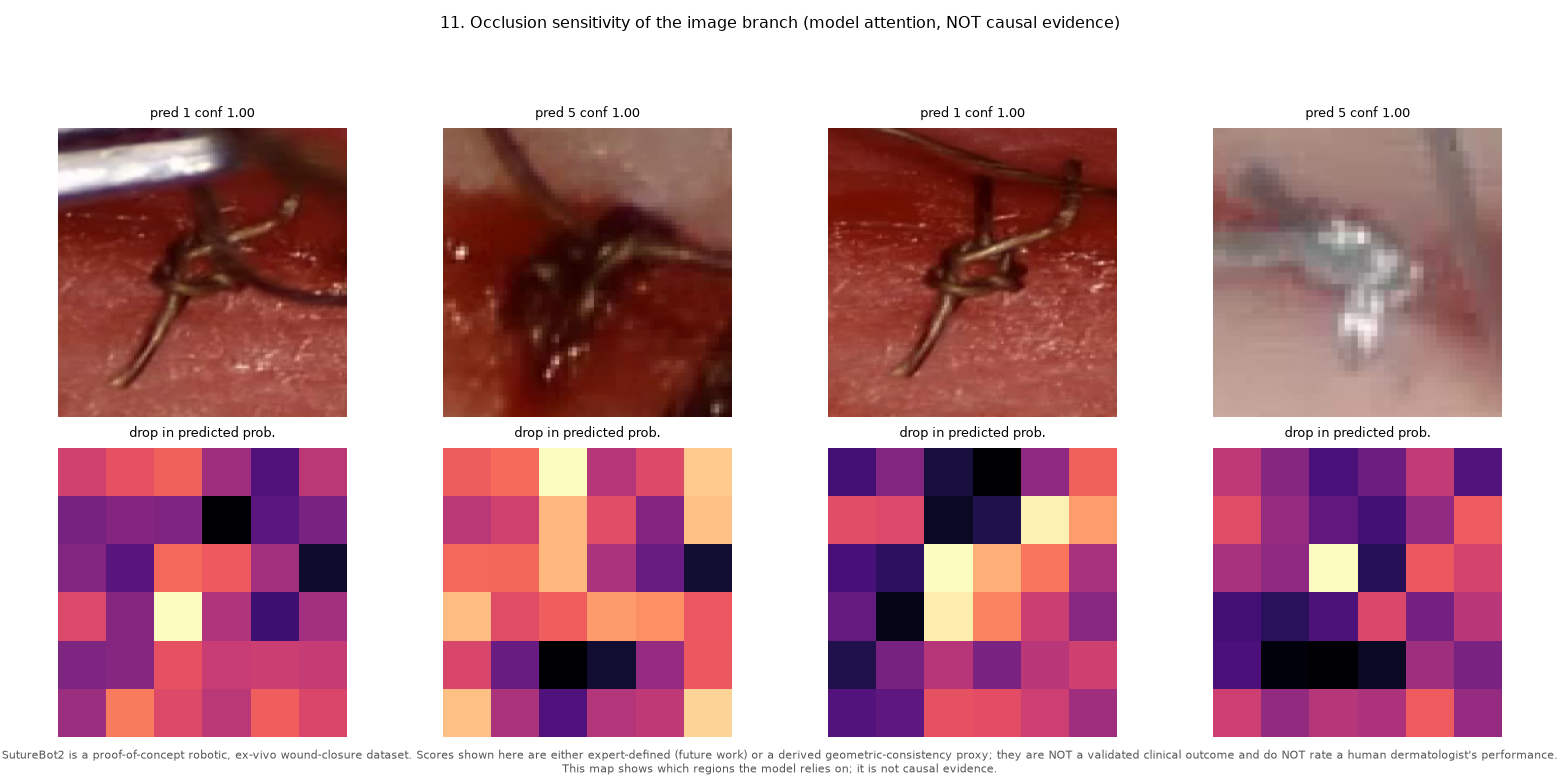

In [27]:
# fig11: occlusion-sensitivity map of the image branch (model attention only).
if primary is not None:
    show_result(viz.gradcam_or_occlusion_map(primary))

## Clinician-facing feedback format

**What this cell does.** Shows the example feedback text the system produces.

**How it works.** `feedback_examples.txt` (written earlier) contains, for a few stitches, exactly the four-line block the research plan specifies: the score, the confidence, the plain-English evidence, and whether the case needs a human review.

**What you should see:** blocks like `Stitch score: 4/5`, `Confidence: 0.81`, `Evidence: ...`, `Review flag: no`. Low-confidence stitches are flagged "review required" instead of being given a confident score.

In [28]:
# Show the clinician-facing feedback examples written by the visualization pipeline.
feedback_path = config.FIGURES_DIR / "feedback_examples.txt"
print(feedback_path.read_text(encoding="utf-8")[:1400] if feedback_path.exists() else "no feedback file yet")

Stitch-level feedback examples
Where is the stitch? -> the provided bounding box.
How good is the stitch? -> the geometric-consistency proxy score below.
SutureBot2 is a proof-of-concept robotic, ex-vivo wound-closure dataset. Scores shown here are either expert-defined (future work) or a derived geometric-consistency proxy; they are NOT a validated clinical outcome and do NOT rate a human dermatologist's performance.

Stitch score: 2/5
Confidence: 0.59
Evidence: stitch bbox barely overlaps the wound; stitch centre sits just outside the wound; spacing between stitches is regular; insertion/exit cross the wound well
Review flag: no

Stitch score: 2/5
Confidence: 0.94
Evidence: stitch bbox barely overlaps the wound; stitch centre sits just outside the wound; spacing between stitches is regular; insertion/exit cross the wound well
Review flag: no

Stitch score: 2/5
Confidence: 0.99
Evidence: stitch bbox barely overlaps the wound; stitch centre lies inside the wound; insertion/exit cross t

## Rebuild every figure in one call (optional)

**What this cell does.** Regenerates **all** figures at once and lists what was produced.

**How it works.** `run_visualization_pipeline()` loops over every plotting function, saves each figure to `figures/`, and returns a dictionary of what it made. Running it guarantees the saved PNGs match the notebook.

**What you should see:** `predictions available: True` and a list of every produced figure key and file name (fig01 ... fig24, plus `feedback`).

In [29]:
# Regenerate every figure at once and list the produced files.
summary = viz.run_visualization_pipeline()
print("predictions available:", summary.get("predictions_available"))
for key in sorted(summary["produced"]):
    print(f"  {key}: {Path(summary['produced'][key]).name}")

predictions available: True
  feedback: feedback_examples.txt
  fig01: fig01_frame_with_boxes.png
  fig02: fig02_stitch_crops_with_scores.png
  fig03: fig03_wound_mask_overlay.png
  fig04: fig04_gt_vs_pred.png
  fig05: fig05_confusion_and_error_matrix.png
  fig06: fig06_metrics_by_fold.png
  fig07: fig07_score_distribution_by_batch_action.png
  fig08: fig08_ablation_comparison.png
  fig09: fig09_calibration.png
  fig10: fig10_failure_gallery.png
  fig11: fig11_attention_map.png
  fig12: fig12_roc_curves.png
  fig13: fig13_binary_roc.png
  fig14: fig14_precision_recall.png
  fig15: fig15_true_vs_pred_scatter.png
  fig16: fig16_confidence_vs_error.png
  fig17: fig17_geometry_correlation_heatmap.png
  fig18: fig18_per_class_metrics.png
  fig19: fig19_batch_score_heatmap.png
  fig20: fig20_probability_heatmap.png
  fig21: fig21_residual_histogram.png
  fig22: fig22_embedding_projection.png
  fig23: fig23_feature_importance.png
  fig24: fig24_training_curves.png


## How to read these figures (paper notes)

**A one-paragraph summary you can reuse in the manuscript.**

- **Figures 1-3** are *localization / geometry* views: where the stitches are and how they sit relative to the wound.
- **Figures 4-5, 9, 12-16, 18, 20-21** are the *ordinal scoring* results, computed strictly on held-out episodes/batches so nothing is inflated by leakage.
- **Figures 6 and 8** are the *generalization and ablation* results — the core methodological contribution.
- **Figures 7, 17, 19, 22-23** characterise the *data, features and explainability*.
- **Figures 10-11** are the *failure analysis and attention* views.

**Never present any of this as clinical effectiveness, dermatologist performance, or healing prediction.** The scores are the geometric-consistency proxy; the honest target is at least 80% within-one accuracy, and human inter-rater agreement (once collected) is the ceiling.